# Part 2 — Mixed effects models
Follows the tutorial's **Mixed effects models** section: first mixed model, crossed vs nested random effects,
the second (nested) model, and random slopes.

| lme4 (R) | statsmodels (Python) |
|---|---|
| `lmer(y ~ x + (1 \| g), data)` | `smf.mixedlm("y ~ x", data, groups=data["g"]).fit()` |
| `(1 + x \| g)` | `groups="g", re_formula="~x"` |
| extra random intercept nested in `g`: `(1 \| g:h)` | `vc_formula={"h": "0 + C(h)"}` |
| crossed random effects `(1 \| a) + (1 \| b)` | one dummy group for everyone + `vc_formula` for `a` and `b` |
| `VarCorr(m)` | `m.cov_re`, `m.vcomp`, `m.scale` |
| `ranef(m)` | `m.random_effects` |
| `predict(m)` | `m.fittedvalues` (fixed + random) |

statsmodels prints the random-effect **variances** at the bottom of the summary (`Group Var` etc.) and the residual variance as `Scale`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings("ignore")          # statsmodels convergence chatter; check m.converged instead
pd.set_option("display.width", 140)

# dragons.csv sits next to this notebook (converted from the tutorial's dragons.RData).
# To read the original RData instead:  import pyreadr; dragons = pyreadr.read_r("dragons.RData")["dragons"]
dragons = pd.read_csv("dragons.csv")
dragons["bodyLength2"] = (dragons["bodyLength"] - dragons["bodyLength"].mean()) / dragons["bodyLength"].std()

## Let's fit our first mixed model

**Tutorial R block 12**
```r
library(lme4)
```
Python equivalent:

In [ ]:
# no extra import needed: statsmodels.formula.api is already loaded as smf

**Tutorial R block 14**
```r
mixed.lmer <- lmer(testScore ~ bodyLength2 + (1|mountainRange), data = dragons)
summary(mixed.lmer)
```
Python equivalent:

In [2]:
mixed_lmer = smf.mixedlm("testScore ~ bodyLength2", dragons,
                         groups=dragons["mountainRange"]).fit(reml=True)
print(mixed_lmer.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: testScore 
No. Observations: 480     Method:             REML      
No. Groups:       8       Scale:              223.8143  
Min. group size:  60      Log-Likelihood:     -1992.8155
Max. group size:  60      Converged:          Yes       
Mean group size:  60.0                                  
--------------------------------------------------------
               Coef.  Std.Err.   z   P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept      50.386    6.552 7.691 0.000 37.545 63.227
bodyLength2     0.538    1.287 0.418 0.676 -1.985  3.060
Group Var     339.666   12.477                          



In [7]:
var_fixed = np.var(mixed_lmer.model.exog @ mixed_lmer.fe_params.values)   # Var(Xβ̂)
var_range = mixed_lmer.cov_re.iloc[0, 0]                          # τ²
var_resid = mixed_lmer.scale                                      # σ²
total = var_fixed + var_range + var_resid

R2_marginal    = var_fixed / total                 # fixed effects only
R2_marginal_random=(var_range + var_resid)/total
R2_conditional = (var_fixed + var_range) / total   # fixed + random

In [8]:
print(var_fixed)
print(R2_marginal_random)
print(R2_marginal)

0.28849994737685597
0.9994882652768441
0.0005117347231558711


- The `bodyLength2` estimate is now small relative to its SE: no detectable effect.
- `Group Var` = variance of the mountain-range intercepts; `Scale` = residual variance.
  The tutorial reports **339.7** and **223.8**; you should get the same.

**Tutorial R block 15** — share of leftover variance due to mountain range
```r
339.7/(339.7 + 223.8)  # ~60 %
```
Python equivalent:

In [9]:
range_var = float(mixed_lmer.cov_re.iloc[0, 0])
resid_var = float(mixed_lmer.scale)
print(f"mountain range variance = {range_var:.1f}, residual = {resid_var:.1f}")
print(f"share due to mountain range = {range_var / (range_var + resid_var):.2f}")

mountain range variance = 339.7, residual = 223.8
share due to mountain range = 0.60


**Tutorial R block 16**
```r
plot(mixed.lmer)  # looks alright, no patterns evident
```
Python equivalent:

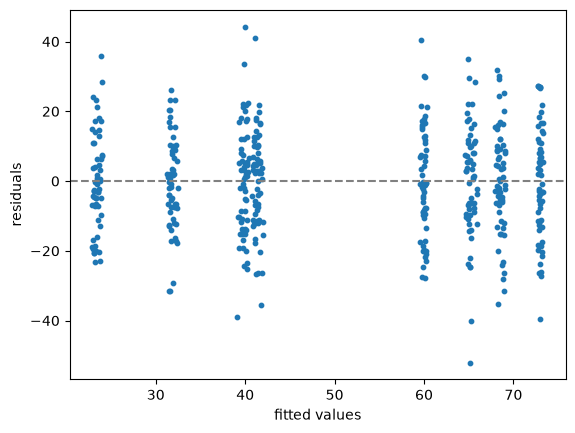

In [10]:
plt.scatter(mixed_lmer.fittedvalues, mixed_lmer.resid, s=10)
plt.axhline(0, ls="--", color="grey")
plt.xlabel("fitted values"); plt.ylabel("residuals"); plt.show()

**Tutorial R block 17**
```r
qqnorm(resid(mixed.lmer))
qqline(resid(mixed.lmer))
```
Python equivalent:

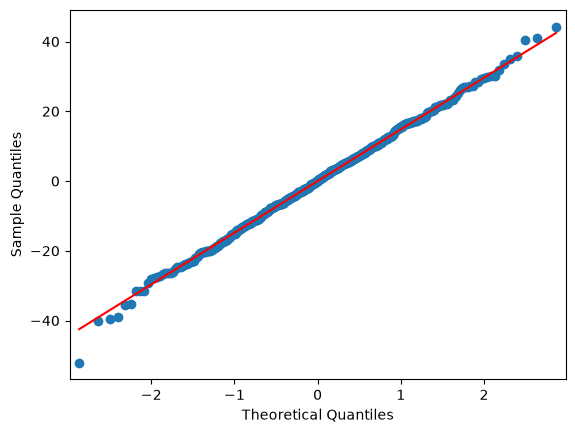

In [11]:
sm.qqplot(mixed_lmer.resid, line="s"); plt.show()

## Types of random effects

**Tutorial R block 18**
```r
head(dragons)
str(dragons)  # three sites per mountain range, eight ranges
```
Python equivalent:

In [12]:
dragons.info()
print(dragons.groupby("mountainRange")["site"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   testScore      480 non-null    float64
 1   bodyLength     480 non-null    float64
 2   mountainRange  480 non-null    str    
 3   X              0 non-null      float64
 4   site           480 non-null    str    
 5   bodyLength2    480 non-null    float64
dtypes: float64(4), str(2)
memory usage: 22.6 KB
mountainRange
Bavarian    [a, b, c]
Central     [a, b, c]
Emmental    [a, b, c]
Julian      [a, b, c]
Ligurian    [a, b, c]
Maritime    [a, b, c]
Sarntal     [a, b, c]
Southern    [a, b, c]
Name: site, dtype: object


### Implicit vs explicit nesting
Site `a` in Bavarian is **not** the same place as site `a` in Central. Giving each a unique label
avoids the model treating them as one site.

**Tutorial R block 19**
```r
dragons <- within(dragons, sample <- factor(mountainRange:site))
```
Python equivalent:

In [13]:
dragons["sample"] = dragons["mountainRange"].astype(str) + ":" + dragons["site"].astype(str)
dragons["sample"].nunique()      # 24 = 8 ranges x 3 sites

24

### The wrong model: treating range and site as crossed
`(1|mountainRange) + (1|site)` pretends there are only three sites (a, b, c) shared by every range.
In statsmodels, crossed random effects use a single dummy group containing everyone, with each factor as a variance component.

**Tutorial R block 20**
```r
mixed.WRONG <- lmer(testScore ~ bodyLength2 + (1|mountainRange) + (1|site), data = dragons)
summary(mixed.WRONG)
```
Python equivalent:

In [14]:
dragons["everyone"] = 1
mixed_WRONG = smf.mixedlm("testScore ~ bodyLength2", dragons, groups=dragons["everyone"],
                          re_formula="0",
                          vc_formula={"mountainRange": "0 + C(mountainRange)",
                                      "site": "0 + C(site)"}).fit(reml=True)
print(mixed_WRONG.summary())

            Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  testScore 
No. Observations:    480      Method:              REML      
No. Groups:          1        Scale:               219.1859  
Min. group size:     480      Log-Likelihood:      -1990.4438
Max. group size:     480      Converged:           Yes       
Mean group size:     480.0                                   
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept          50.386    7.430  6.781 0.000 35.823 64.950
bodyLength2        -2.600    1.841 -1.412 0.158 -6.208  1.009
mountainRange Var 410.001   15.381                           
site Var           10.517    0.889                           



## Our second mixed model (correct nesting)

**Tutorial R block 21**
```r
mixed.lmer2 <- lmer(testScore ~ bodyLength2 + (1|mountainRange) + (1|sample), data = dragons)
summary(mixed.lmer2)
```
Python equivalent:

In [15]:
# sample is nested in mountainRange: group by range, add a random intercept for each sample within it
mixed_lmer2 = smf.mixedlm("testScore ~ bodyLength2", dragons,
                          groups=dragons["mountainRange"],
                          re_formula="1",                       # random intercept for range
                          vc_formula={"sample": "0 + C(sample)"}).fit(reml=True)
print(mixed_lmer2.summary())

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: testScore 
No. Observations: 480     Method:             REML      
No. Groups:       8       Scale:              208.5790  
Min. group size:  60      Log-Likelihood:     -1985.1947
Max. group size:  60      Converged:          Yes       
Mean group size:  60.0                                  
--------------------------------------------------------
               Coef.  Std.Err.   z   P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept      50.386    6.507 7.743 0.000 37.632 63.140
bodyLength2     0.831    1.711 0.486 0.627 -2.522  4.184
Group Var     327.591   12.838                          
sample Var     23.092    0.840                          



`Group Var` = mountain-range variance; `sample Var` = site-within-range variance; `Scale` = residual. lme4 gives about 327.6, 23.1 and 208.6.

**Watch out:** when you use `vc_formula`, statsmodels drops the group's own random intercept unless you also write `re_formula="1"`. Without it, this model would silently have no mountain-range intercept.

**Tutorial R block 22**
```r
(mm_plot <- ggplot(dragons, aes(x = bodyLength, y = testScore, colour = site)) +
  facet_wrap(~mountainRange, nrow=2) + geom_point(alpha = 0.5) +
  geom_line(data = cbind(dragons, pred = predict(mixed.lmer2)), aes(y = pred), size = 1) + ...)
```
Python equivalent:

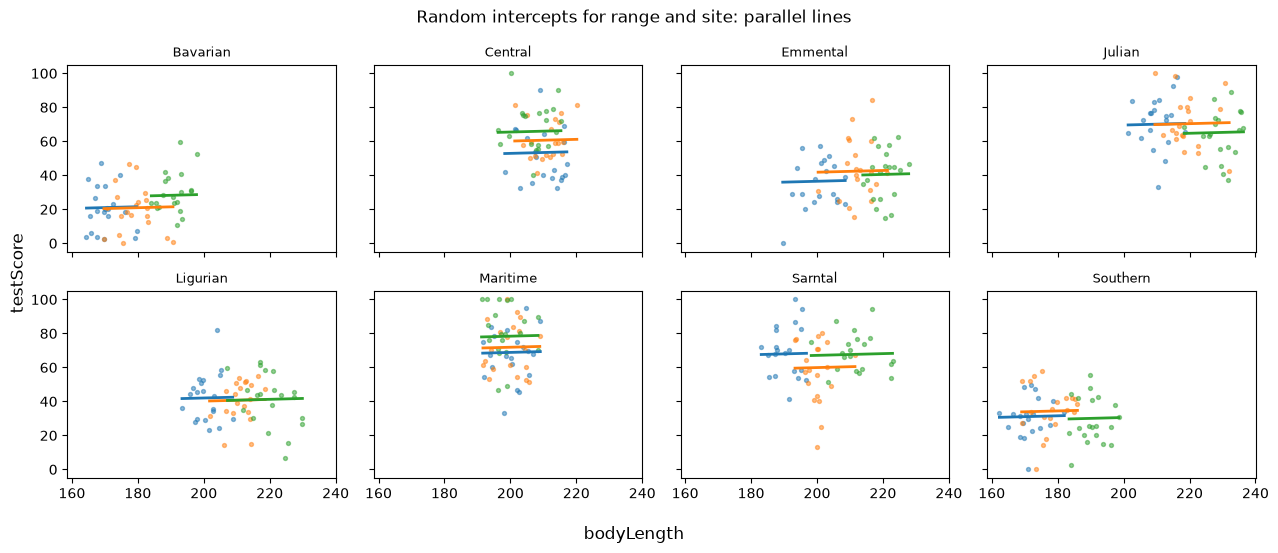

In [16]:
def facet_predictions(model, title):
    d = dragons.assign(pred=model.fittedvalues)       # fixed + random effects, like predict() in lme4
    fig, axs = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True, sharey=True)
    for ax, r in zip(axs.flat, sorted(d.mountainRange.unique())):
        g = d[d.mountainRange == r]
        for s, gs in g.groupby("site"):
            ax.scatter(gs.bodyLength, gs.testScore, s=8, alpha=0.5)
            gs = gs.sort_values("bodyLength")
            ax.plot(gs.bodyLength, gs.pred, lw=2)
        ax.set_title(r, fontsize=9)
    fig.suptitle(title); fig.supxlabel("bodyLength"); fig.supylabel("testScore")
    plt.tight_layout(); plt.show()

facet_predictions(mixed_lmer2, "Random intercepts for range and site: parallel lines")

## Introducing random slopes

**Tutorial R block 23**
```r
mixed.ranslope <- lmer(testScore ~ bodyLength2 + (1 + bodyLength2|mountainRange/site), data = dragons)
summary(mixed.ranslope)
```
Python equivalent:

`(1 + bodyLength2 | mountainRange/site)` expands to
`(1 + bodyLength2 | mountainRange) + (1 + bodyLength2 | mountainRange:site)`:
a random intercept and slope for each range, and again for each site within a range.

statsmodels can match the range part exactly (`re_formula="~bodyLength2"`). For the site part it uses
separate variance components for the site intercepts and slopes, so the **intercept–slope correlation at the
site level is fixed at 0** (lme4 estimates it). Estimates will be close but not identical to the tutorial.

This model is hard to fit: the site-level slope variance goes to 0 (a **singular / boundary fit**; lme4 warns about the same thing). The default optimizer fails here, so `method=["powell", "lbfgs"]` is used. When a variance is estimated at 0, that random term isn't supported by the data and the simpler model is usually preferred.

In [17]:
mixed_ranslope = smf.mixedlm("testScore ~ bodyLength2", dragons,
                             groups=dragons["mountainRange"],
                             re_formula="~bodyLength2",                       # (1 + bodyLength2 | mountainRange)
                             vc_formula={"sample": "0 + C(sample)",            # site intercepts
                                         "sample_slope": "0 + C(sample):bodyLength2"}  # site slopes
                             ).fit(reml=True, method=["powell", "lbfgs"])
print("converged:", mixed_ranslope.converged)
print(mixed_ranslope.summary())

converged: True
              Mixed Linear Model Regression Results
Model:                MixedLM    Dependent Variable:    testScore 
No. Observations:     480        Method:                REML      
No. Groups:           8          Scale:                 208.7364  
Min. group size:      60         Log-Likelihood:        -1984.3442
Max. group size:      60         Converged:             Yes       
Mean group size:      60.0                                        
------------------------------------------------------------------
                         Coef.  Std.Err.   z   P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept                51.371    6.522 7.876 0.000 38.587 64.154
bodyLength2               0.561    1.866 0.301 0.764 -3.097  4.219
Group Var               306.373   11.882                          
Group x bodyLength2 Cov -40.285    3.534                          
bodyLength2 Var           5.297    6.145                     

**Tutorial R block 24**
```r
### plot: same faceted plot with predict(mixed.ranslope)
```
Python equivalent:

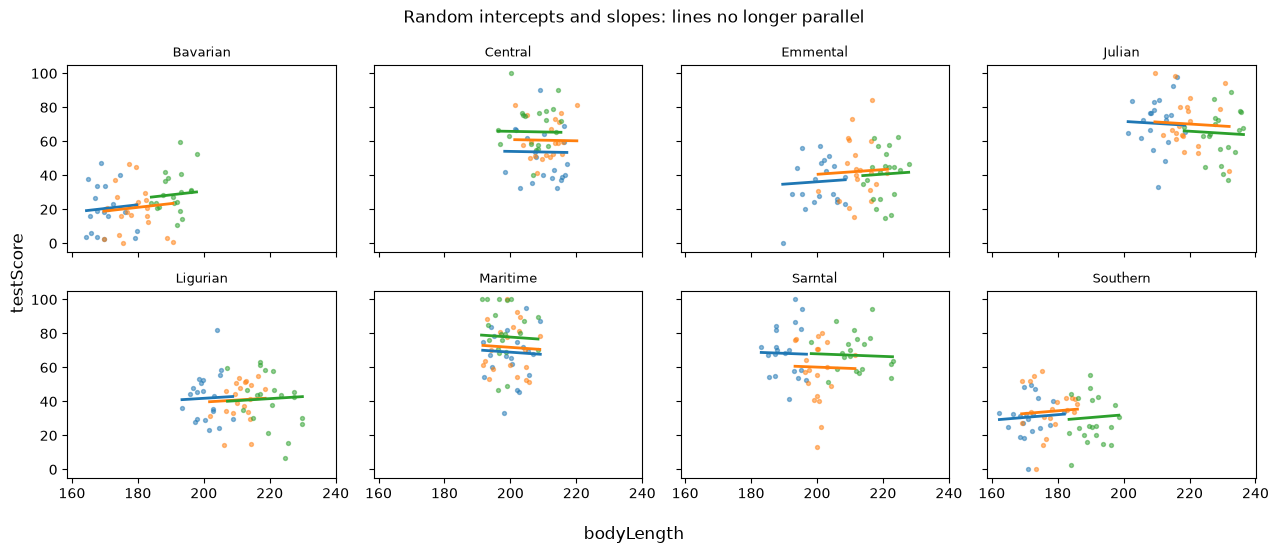

In [18]:
facet_predictions(mixed_ranslope, "Random intercepts and slopes: lines no longer parallel")

**Reading a random slope (tutorial example, Maritime range):** the random effects are *deviations* from the fixed estimates.
Maritime's slope = fixed slope + Maritime's slope deviation; its intercept = fixed intercept + its intercept deviation.

In [19]:
fe = mixed_ranslope.fe_params
re_mar = mixed_ranslope.random_effects["Maritime"]
print(re_mar.round(2))
print("Maritime intercept =", round(fe["Intercept"] + re_mar["Group"], 2))
print("Maritime slope     =", round(fe["bodyLength2"] + re_mar["bodyLength2"], 2))

Group                                              20.84
bodyLength2                                        -2.74
sample[C(sample)[Maritime:a]]                      -3.42
sample[C(sample)[Maritime:b]]                      -0.57
sample[C(sample)[Maritime:c]]                       5.47
sample_slope[C(sample)[Maritime:a]:bodyLength2]     0.00
sample_slope[C(sample)[Maritime:b]:bodyLength2]     0.00
sample_slope[C(sample)[Maritime:c]:bodyLength2]    -0.00
dtype: float64
Maritime intercept = 72.21
Maritime slope     = -2.18
